## IIR Notch FIltering

Here’s a Direct Form II (canonical) implementation of the classic second-order IIR notch:

\begin{equation*}
\begin{align*}
H(z) = K \, \frac{1 - 2 \cos(\omega_0) \, z^{-1} + z^{-2}}
                {1 - 2 r \cos(\omega_0) \, z^{-1} + r^2 z^{-2}}

   \quad \text{where} \quad
   K = \frac{1 + 2 r \cos(\omega_0) + r^2}{2 + 2 \cos(\omega_0)}
\end{align*}
\end{equation*}

where $ω0=2𝜋𝑓0/𝑓𝑠$ and $0 < r < 1$ controls the notch bandwidth (poles at radius r near the zeros)

Note: transposed DF-II (often better numerically).

The following sections show the trade-offs

 - Too narrow bandwidth takes a long time to converge also can't handle the variation in frequency for "50 Hz" mains.
 - Too wide bandwidth causes unwanted attenutation of out-of-band frequencies


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as sig
from scipy.io import wavfile


In [2]:
# Wrapper to take a filename and publish an html <audio> tag to listen to it

# https://nbviewer.org/gist/Carreau/5507501/the%20sound%20of%20hydrogen.ipynb

from IPython.core.display import HTML

def wavPlayer(filepath):
  """ will display html 5 player for compatible browser

  Parameters :
  ------------
  filepath : relative filepath with respect to the notebook directory ( where the .ipynb are not cwd)
              of the file to play

  The browser need to know how to play wav through html5.

  there is no autoplay to prevent file playing when the browser opens
  """

  src = """
  <head>
  <meta http-equiv="Content-Type" content="text/html; charset=utf-8">
  <title>Simple Test</title>
  </head>

  <body>
  <audio controls="controls" style="width:600px" >
    <source src="%s" type="audio/wav" />
    Your browser does not support the audio element.
  </audio>
  </body>
  """%(filepath)
  display(HTML(src))

In [3]:
# ----- Direct Form II (canonical) filtering implementation -----
def iir_filter_dfII(x, b, a):
  # Assumes a[0] == 1
  w1 = 0.0
  w2 = 0.0
  y = np.empty_like(x, dtype=float)
  for n, xn in enumerate(x):
    w0_s = xn - a[1]*w1 - a[2]*w2         # state update (internal node)
    yn = b[0]*w0_s + b[1]*w1 + b[2]*w2    # output
    y[n] = yn
    w2 = w1
    w1 = w0_s
  return y


In [4]:
fs, data = wavfile.read('Alive_1kHz_Tone_10s_mono.wav')

# Original Signal
wavPlayer("Alive_1kHz_Tone_10s_mono.wav")


r = 0.9929015212007221
Coefficients:
b = [ 0.99291418 -1.9657069   0.99291418]
a = [ 1.         -1.96568184  0.98585343]


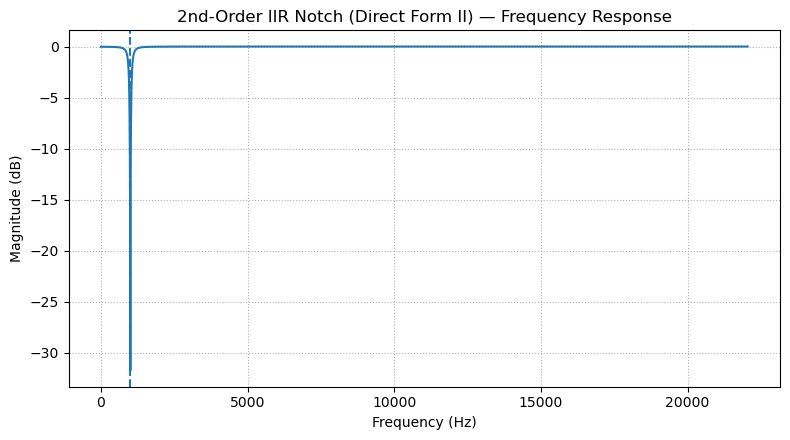

In [5]:
# ----- Design parameters -----
tone_freq = 1000.0              # Tone frequency (Hz)
notch_bandwidth = 100.0         # Notch bandwidth (Hz)

# Computing radius (r) and frequency (ω_0)
r = np.exp(-np.pi * notch_bandwidth / fs)
w0 = 2 * np.pi * tone_freq / fs # radians/sample

# Gain normalization per DSP.SE post:
K = (1 + 2*r*np.cos(w0) + r**2) / (2 + 2*np.cos(w0))

# Coefficients (b for numerator, a for denominator with a0=1)
b = np.array([K, -2*K*np.cos(w0), K])
a = np.array([1.0, -2*r*np.cos(w0), r**2])

print("r =", r)
print("Coefficients:")
print("b =", b)
print("a =", a)

# ----- Frequency response -----
w, H = sig.freqz(b, a, worN=4096, fs=fs)
mag_db = 20*np.log10(np.maximum(np.abs(H), 1e-12))

plt.figure(figsize=(8,4.5))
plt.plot(w, mag_db, linewidth=1.5)
plt.axvline(tone_freq, linestyle="--")
plt.title("2nd-Order IIR Notch (Direct Form II) — Frequency Response")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")
plt.grid(True, which="both", linestyle=":")
plt.tight_layout()


In [6]:
# Long filter has large group delay
y = iir_filter_dfII(data, b, a)

wavfile.write('Alive_1kHz_Tone_10s_filtered_mono.wav', fs, y.astype(data.dtype))
wavPlayer("Alive_1kHz_Tone_10s_filtered_mono.wav")


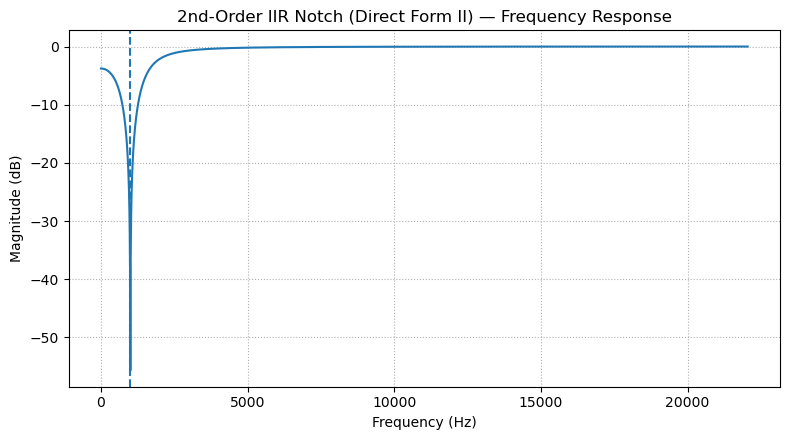

In [7]:
# Short filter impacts overall frequency response

r = 0.9              # pole radius 0<r<1; closer to 1 => narrower notch

# Gain normalization per DSP.SE post:
K = (1 + 2*r*np.cos(w0) + r**2) / (2 + 2*np.cos(w0))

# Coefficients (b for numerator, a for denominator with a0=1)
b = np.array([K, -2*K*np.cos(w0), K])
a = np.array([1.0, -2*r*np.cos(w0), r**2])

# ----- Frequency response -----
w, H = sig.freqz(b, a, worN=4096, fs=fs)
mag_db = 20*np.log10(np.maximum(np.abs(H), 1e-12))

plt.figure(figsize=(8,4.5))
plt.plot(w, mag_db, linewidth=1.5)
plt.axvline(tone_freq, linestyle="--")
plt.title("2nd-Order IIR Notch (Direct Form II) — Frequency Response")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")
plt.grid(True, which="both", linestyle=":")
plt.tight_layout()


In [9]:
# Filter
y = iir_filter_dfII(data, b, a)

wavfile.write('Alive_1kHz_Tone_10s_filtered_mono_2.wav', fs, y.astype(data.dtype))
wavPlayer("Alive_1kHz_Tone_10s_filtered_mono_2.wav")
